# London street crime: patterns in outcomes, time and geography

**Statistics for AI and Data Science — Coursework 1**  
**Analysis period:** July 2024 to June 2025

### AI Use Statement

I used OpenAI (ChatGPT) mainly to help me understand the assignment brief, check my Python code, and clarify some of my interpretations. However, this assignment is my own independent work, based on my coding knowledge, understanding of the requirements, and personal analysis. AI was only used as a supporting tool throughout the process.
### Scope and limitations

The analysis uses the supplied, modified Metropolitan Police street-crime data, 2021 Census population by LSOA, and LSOA boundaries. The records are not necessarily an unbiased census of offending. Descriptions refer to **recorded crime**, not to all crime occurring in London. Comparisons are descriptive rather than causal; no significance tests are performed.

The five questions are: (1) crime type and charging, (2) monthly variation, (3) LSOA crime rates, (4) mix by London region, and (5) youth proportion and crime rate. This notebook addresses **all five parts** of the coursework.

## Set-up and initial review

Place this notebook **in the same directory** as the original files `cw1-street-outcome.csv`, `LSOA_data.csv` and `LSOA_England_geom.gpkg`. Relative paths keep it portable between computers. We load the crime data now; population and geometry are needed in later parts.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
crimes = pd.read_csv(DATA_DIR / "cw1-street-outcome.csv")
print(f"Crime records: {len(crimes):,}")
print(f"Columns: {list(crimes.columns)}")
display(crimes.head(3))

Crime records: 902,579
Columns: ['CrimeID', 'Month', 'Longitude', 'Latitude', 'Location', 'LSOACode', 'LSOAName', 'CrimeType', 'Outcome']


,CrimeID,Month,Longitude,Latitude,Location,LSOACode,LSOAName,CrimeType,Outcome
0,77463cb80995854fa6f17471e3cf23ac335b46c3390f56...,2024-07,0.145722,51.594296,On or near Providence Place,E01000027,Barking and Dagenham 001A,Burglary,Investigation complete; no suspect identified
1,b190754617a16d461e2ac0c2f96140e9e67a891812c933...,2024-07,0.140127,51.588913,On or near Beansland Grove,E01000027,Barking and Dagenham 001A,Drugs,Unable to prosecute suspect
2,6af09c497a07b40653f5674593cef12336f8a1dc163632...,2024-07,0.145722,51.594296,On or near Providence Place,E01000027,Barking and Dagenham 001A,Other theft,Unable to prosecute suspect


We check the recording period, missing outcomes, and duplicate identifiers before calculating percentages. A row is used as the unit of analysis because repeated identifiers cannot always be uniquely reconciled without extra source information.

In [2]:
print("Months:", sorted(crimes["Month"].unique()))
print("Missing outcomes:", crimes["Outcome"].isna().sum())
print("Repeated CrimeIDs:", crimes["CrimeID"].duplicated().sum())
print("Exactly duplicated rows:", crimes.duplicated().sum())
print("Crime types:", crimes["CrimeType"].nunique())
print("Outcome categories:", crimes["Outcome"].nunique())

Months: ['2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12', '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06']
Missing outcomes: 0
Repeated CrimeIDs: 699
Exactly duplicated rows: 196
Crime types: 13
Outcome categories: 11


**Data-quality choice.** The provided file contains repeated `CrimeID` values. Some records sharing an ID have different outcomes or crime types, so discarding them by ID would arbitrarily remove data. We count rows as supplied and flag this as a limitation. We do not claim every ID uniquely identifies one observation in this file.

## Part 1 — Does the proportion of crimes charged vary by crime type?

### Interpretation and transformation

We classify the 11 recorded outcomes using the mapping in the coursework brief. `Awaiting court outcome`, `Court result unavailable` and `Suspect charged` mean **Charged** for this task. `Status update unavailable` means **Unknown**. All seven other specified outcomes mean **Not charged**.

For each crime type, the denominator is **all records with a known charging classification**, and the numerator is the number classified **Charged**:

**Percentage charged (%) = 100 × (charged records / records with known charging status).**

This is a descriptive measure of whether an outcome indicates a charge; it is **not** a conviction rate.

In [3]:
outcome_classification = {
    "Action to be taken by another organisation": "Not charged",
    "Awaiting court outcome": "Charged",
    "Court result unavailable": "Charged",
    "Further action is not in the public interest": "Not charged",
    "Investigation complete; no suspect identified": "Not charged",
    "Local resolution": "Not charged",
    "Offender given a caution": "Not charged",
    "Offender given penalty notice": "Not charged",
    "Status update unavailable": "Unknown",
    "Suspect charged": "Charged",
    "Unable to prosecute suspect": "Not charged",
}
crimes["ChargeStatus"] = crimes["Outcome"].map(outcome_classification)
assert crimes["ChargeStatus"].notna().all(), "An outcome is missing from the mapping"
print(crimes["ChargeStatus"].value_counts().to_string())

ChargeStatus
Not charged    808923
Charged         47259
Unknown         46397


We omit only **Unknown** from the charging percentage, not from other unrelated analyses. A Boolean column (`True` for charged) lets Pandas count charges by summing, because `True` counts as 1 and `False` as 0.

In [4]:
known_outcome = crimes.loc[crimes["ChargeStatus"] != "Unknown"].copy()
known_outcome["WasCharged"] = known_outcome["ChargeStatus"] == "Charged"

charge_by_type = known_outcome.groupby("CrimeType").agg(
    KnownOutcomes=("WasCharged", "size"),
    Charged=("WasCharged", "sum"),
)
charge_by_type["PercentageCharged"] = (
    100 * charge_by_type["Charged"] / charge_by_type["KnownOutcomes"]
)
charge_by_type = charge_by_type.sort_values("PercentageCharged")
display(charge_by_type.round(2))

,KnownOutcomes,Charged,PercentageCharged
CrimeType,,,
Theft from the person,92208,529,0.57
Other theft,98315,665,0.68
Vehicle crime,85941,838,0.98
Bicycle theft,14061,138,0.98
Criminal damage and arson,52786,2316,4.39
Burglary,47732,2556,5.35
Robbery,30500,1786,5.86
Shoplifting,86515,5790,6.69
Violence and sexual offences,236263,18250,7.72


### Comparing charging percentages

Each bar is **the percentage charged within one crime type**, not its share of all recorded crimes. The different denominators are shown in the table above.

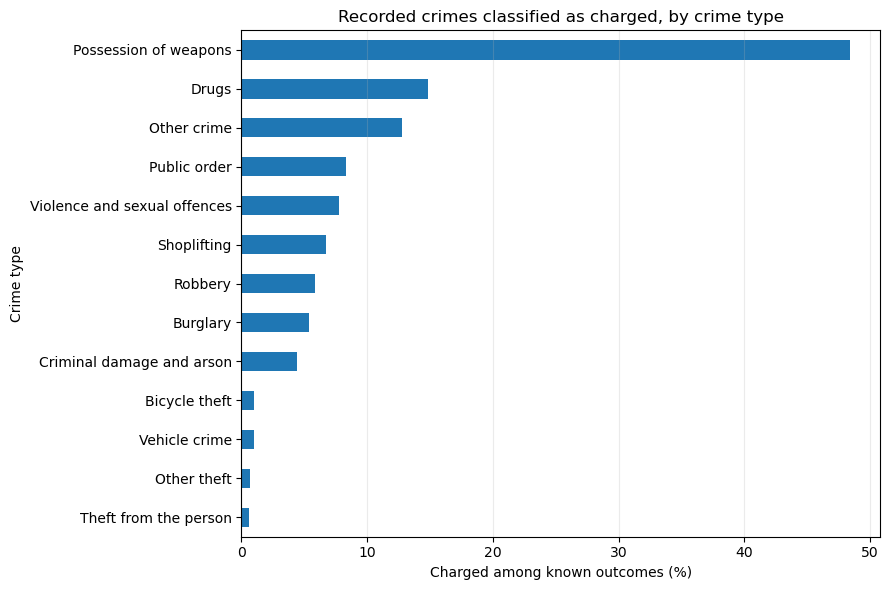

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
charge_by_type["PercentageCharged"].plot.barh(ax=ax)
ax.set_title("Recorded crimes classified as charged, by crime type")
ax.set_xlabel("Charged among known outcomes (%)")
ax.set_ylabel("Crime type")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**What the data show.** In this file, *Possession of weapons* has the highest charged percentage (about **48.4%**) and *Theft from the person* the lowest (about **0.6%**) among records with a known classification. Crime type is therefore associated with substantial **descriptive variation** in the proportion of records classified as charged. This should not be interpreted as evidence that any crime type is intrinsically easier to prosecute: reporting, recording practices and case circumstances may differ.

### When no one is charged: two examples

For an interpretable contrast, we compare **Vehicle crime** with **Drugs**. We use only records classified **Not charged** for these two types. For each type, we calculate what percentage of its non charged records ends in each outcome. **Each crime-type column therefore adds to 100%.**

In [6]:
two_types = ["Vehicle crime", "Drugs"]
no_charge_two = crimes.loc[
    (crimes["ChargeStatus"] == "Not charged") &
    (crimes["CrimeType"].isin(two_types))
]
no_charge_counts = pd.crosstab(no_charge_two["Outcome"], no_charge_two["CrimeType"])
no_charge_percent = no_charge_counts.div(no_charge_counts.sum(axis=0), axis=1) * 100
print("Non-charged records by crime type:")
print(no_charge_counts.sum(axis=0).to_string())
display(no_charge_percent.round(1))

Non-charged records by crime type:
CrimeType
Drugs            38253
Vehicle crime    85103


CrimeType,Drugs,Vehicle crime
Outcome,,
Action to be taken by another organisation,0.0,0.0
Further action is not in the public interest,1.3,0.1
Investigation complete; no suspect identified,4.2,94.0
Local resolution,34.9,0.0
Offender given a caution,1.3,0.0
Offender given penalty notice,5.8,0.0
Unable to prosecute suspect,52.5,5.8


Here the denominator changes: percentages describe the **mix of non-charged outcomes**, not the overall charge rate. A grouped bar chart makes individual outcome categories easy to compare.

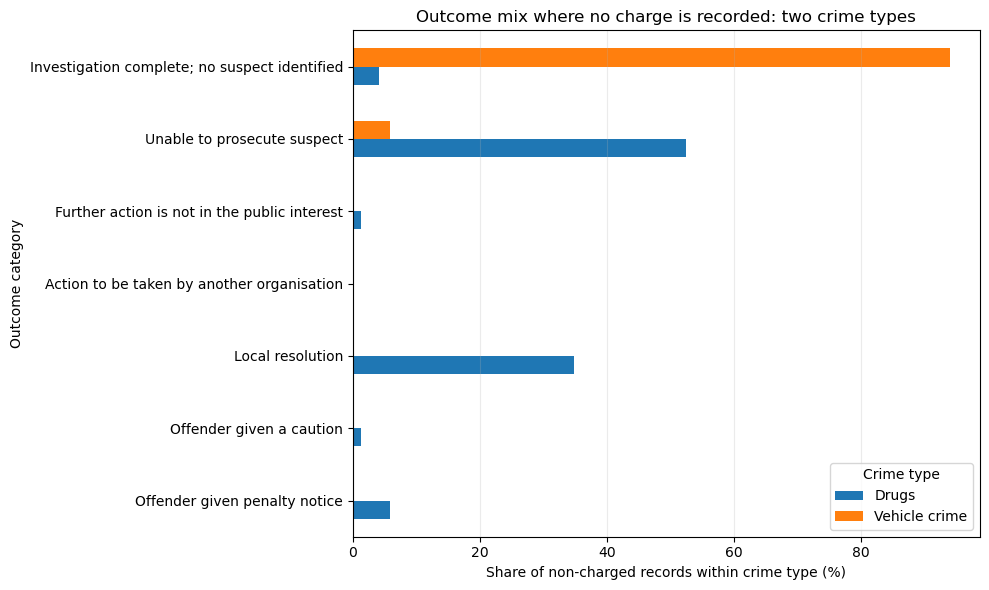

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
no_charge_percent.sort_values("Vehicle crime").plot.barh(ax=ax)
ax.set_title("Outcome mix where no charge is recorded: two crime types")
ax.set_xlabel("Share of non-charged records within crime type (%)")
ax.set_ylabel("Outcome category")
ax.legend(title="Crime type")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation.** Among non charged **Vehicle crime** records, about **94.0%** are categorised *Investigation complete; no suspect identified*. The corresponding percentage for **Drugs** is about **4.2%**. For non charged **Drugs** records, *Unable to prosecute suspect* accounts for about **52.5%**, and *Local resolution* about **34.9%**. Therefore, the reasons or recorded outcomes for not charging differ greatly between these two crime types.

**Limitations.** Outcome classifications are simplified by the coursework; “charged” does not imply a guilty verdict. Unknown charging outcomes are excluded from charged proportions, and the recording/reporting process may introduce bias. The figures cover a single 12-month period and cannot establish why outcomes differ.

## Part 2 — Does recorded crime vary by time of year?

### Approach

I treat each row in the supplied crime file as one recorded incident, as in Part 1. The data cover **July 2024 to June 2025**, so I compare the months in chronological order. I first count all crime types together, then look at each crime type separately.

Monthly totals are useful, but they are affected by the number of days in a month. I therefore also calculate **crimes per day = monthly count ÷ days in month**. This makes comparisons such as January versus February fairer. These figures describe *recorded* crime, rather than every crime that occurred.

In [8]:
# Make sure the months are in calendar order, not alphabetical order.
crimes["MonthDate"] = pd.to_datetime(crimes["Month"], format="%Y-%m")

monthly_summary = crimes.groupby("MonthDate").size().to_frame("RecordedCrimes")
monthly_summary["DaysInMonth"] = monthly_summary.index.days_in_month
monthly_summary["CrimesPerDay"] = (
    monthly_summary["RecordedCrimes"] / monthly_summary["DaysInMonth"]
)

assert len(monthly_summary) == 12
assert monthly_summary["RecordedCrimes"].sum() == len(crimes)
display(monthly_summary.round(1))

,RecordedCrimes,DaysInMonth,CrimesPerDay
MonthDate,,,
2024-07-01,77488,31,2499.6
2024-08-01,75116,31,2423.1
2024-09-01,74260,30,2475.3
2024-10-01,80140,31,2585.2
2024-11-01,79392,30,2646.4
2024-12-01,74791,31,2412.6
2025-01-01,70523,31,2274.9
2025-02-01,68065,28,2430.9
2025-03-01,74302,31,2396.8


### Overall variation across the 12 months

The top chart shows **the total number of crimes recorded each month**. The bottom chart shows **the average number recorded per day**, which corrects for differences in month length. I use both because a short month can have fewer crimes in total without having a lower daily rate.

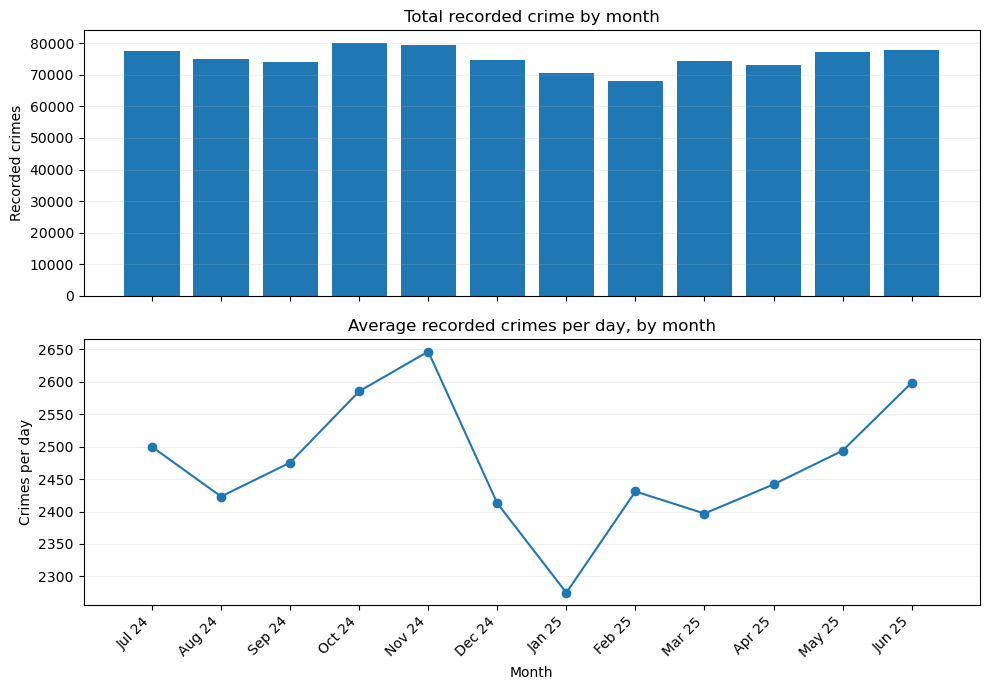

In [9]:
month_labels = monthly_summary.index.strftime("%b %y")
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].bar(month_labels, monthly_summary["RecordedCrimes"])
axes[0].set_title("Total recorded crime by month")
axes[0].set_ylabel("Recorded crimes")
axes[0].grid(axis="y", alpha=0.2)

axes[1].plot(month_labels, monthly_summary["CrimesPerDay"], marker="o")
axes[1].set_title("Average recorded crimes per day, by month")
axes[1].set_ylabel("Crimes per day")
axes[1].set_xlabel("Month")
axes[1].grid(axis="y", alpha=0.2)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
plt.show()

**Comment.** October 2024 has the highest monthly total (**80,140**), while February 2025 has the lowest (**68,065**). However, February has only 28 days. When month length is taken into account, **November 2024** has the highest daily average (around **2,646**) and **January 2025** the lowest (around **2,275**). Crime therefore varies across these months, but the apparent difference depends partly on how it is measured.

### How the individual crime types vary

To compare types of different sizes, I work out the average **daily count for each crime type in each month**. I then express it as a percentage of that crime type's daily average over the **whole 365-day period**:

**Monthly index = 100 × (crime type's daily average in that month ÷ its daily average across the study period).**

An index of **100** means a typical daily level for that type; **120** means 20% above its usual level; **80** means 20% below. This shows **variation within each crime type**. It does *not* show which types are most common overall.

In [10]:
# Each cell counts one crime type in one month.
monthly_by_type = pd.crosstab(crimes["MonthDate"], crimes["CrimeType"])

# Adjust each monthly count for the number of days in that month.
daily_by_type = monthly_by_type.div(monthly_by_type.index.days_in_month, axis=0)

# Compare each month's daily count with that type's daily average for the full period.
period_daily_average = monthly_by_type.sum(axis=0) / monthly_summary["DaysInMonth"].sum()
type_index = daily_by_type.div(period_daily_average, axis=1) * 100

assert monthly_by_type.to_numpy().sum() == len(crimes)
display(type_index.round(0))

CrimeType,Bicycle theft,Burglary,Criminal damage and arson,Drugs,Other crime,Other theft,Possession of weapons,Public order,Robbery,Shoplifting,Theft from the person,Vehicle crime,Violence and sexual offences
MonthDate,,,,,,,,,,,,,
2024-07-01,118.0,99.0,112.0,72.0,87.0,108.0,86.0,109.0,97.0,104.0,91.0,105.0,102.0
2024-08-01,120.0,99.0,107.0,76.0,88.0,100.0,96.0,107.0,98.0,106.0,87.0,104.0,96.0
2024-09-01,126.0,100.0,101.0,95.0,102.0,100.0,107.0,102.0,102.0,107.0,88.0,105.0,99.0
2024-10-01,120.0,109.0,98.0,99.0,108.0,107.0,96.0,103.0,112.0,107.0,110.0,109.0,99.0
2024-11-01,106.0,113.0,100.0,107.0,105.0,109.0,92.0,99.0,109.0,107.0,130.0,108.0,100.0
2024-12-01,70.0,113.0,89.0,97.0,92.0,104.0,77.0,85.0,99.0,87.0,119.0,94.0,96.0
2025-01-01,68.0,106.0,89.0,101.0,103.0,92.0,80.0,85.0,90.0,91.0,93.0,97.0,90.0
2025-02-01,75.0,98.0,96.0,101.0,101.0,97.0,92.0,88.0,99.0,98.0,109.0,104.0,96.0
2025-03-01,83.0,94.0,97.0,99.0,107.0,90.0,106.0,96.0,94.0,93.0,102.0,94.0,101.0


The heatmap below includes **all 13 crime types**. Each row shows one crime type across the 12 months. The colours indicate whether its daily level is lower or higher than its own average for the year; they are not a comparison of raw crime volumes between types.

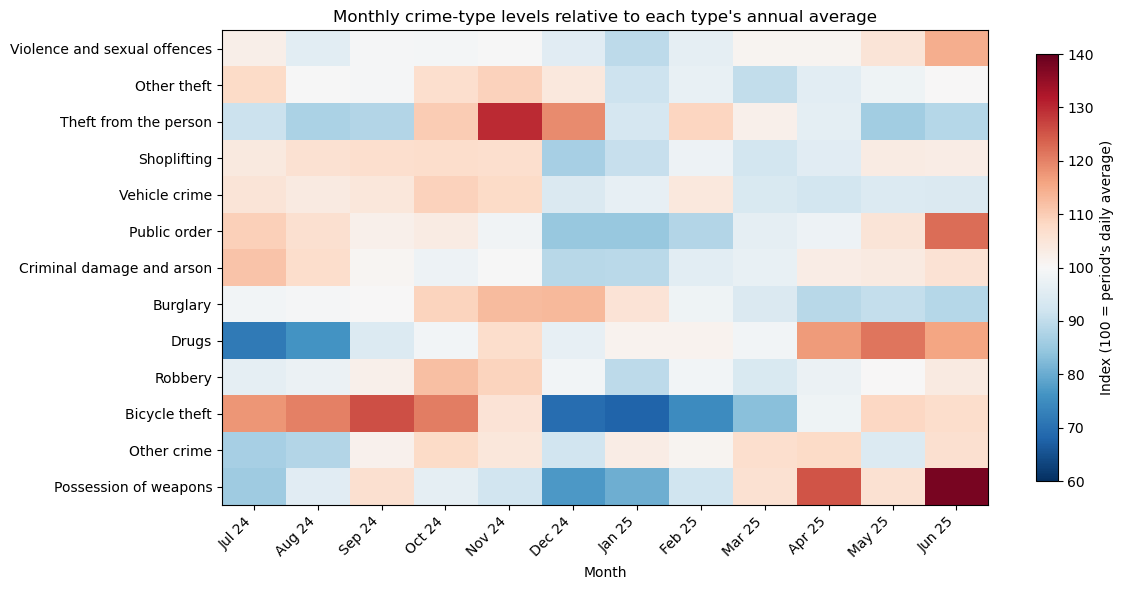

In [11]:
# Put crime types in order of how frequently they appear in the dataset.
crime_type_order = crimes["CrimeType"].value_counts().index
type_index_plot = type_index[crime_type_order].T

fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(type_index_plot, aspect="auto", cmap="RdBu_r", vmin=60, vmax=140)
ax.set_xticks(range(len(month_labels)), labels=month_labels, rotation=45, ha="right")
ax.set_yticks(range(len(crime_type_order)), labels=crime_type_order)
ax.set_title("Monthly crime-type levels relative to each type's annual average")
ax.set_xlabel("Month")
fig.colorbar(image, ax=ax, label="Index (100 = period's daily average)", shrink=0.9)
fig.tight_layout()
plt.show()

**Comment.** The pattern is not the same for every type. *Theft from the person* reaches about **130%** of its usual daily level in November 2024, whereas *Violence and sexual offences* is highest in June 2025 at about **114%** of its usual daily level. *Bicycle theft* is relatively low in January 2025 (around **68%**) and high in September 2024 (around **126%**). This suggests that the distribution of recorded crime across months differs by crime type, rather than all categories rising and falling together.

**Limitations.** We have **only one 12-month period**. That is enough to describe monthly differences in this dataset, but not enough to show that a pattern repeats every year or to separate seasonality from a short term change. Monthly counts also hide differences between weekdays and weekends, and they can be affected by reporting and recording practices. The charts show associations and fluctuations, not their causes. No statistical tests are used, in line with the brief.



## Part 3 — Crime rate differences between London LSOAs

### How the rate is defined

An LSOA is a small geographical area. To compare areas of different sizes, I use **recorded crimes per 1,000 residents** during July 2024–June 2025:

**Annual recorded-crime rate = (number of recorded crimes in the LSOA ÷ 2021 Census population) × 1,000.**

I count **all crime types**, use `LSOACode` to match the crime records to population, and take London's LSOAs to be those in the 33 local authorities whose `PartOfCode` starts with `E09`. Each row in the crime dataset is counted once, following the choice explained in Part 1. Areas with no matching crime records receive a count of zero, rather than being dropped.

This rate measures **recorded incidents per resident**, not the probability that a particular resident experiences a crime. People can work, shop or travel through an LSOA without living there. Also, the population figures refer to 2021, while the crime counts are from 2024–25.

In [12]:
import numpy as np
import geopandas as gpd

population = pd.read_csv(DATA_DIR / "LSOA_data.csv")
london_population = population.loc[
    population["PartOfCode"].str.startswith("E09")
].copy()

# Count incidents at each LSOA. Keep areas with no recorded incidents.
crime_counts = crimes.groupby("LSOACode").size().rename("CrimeCount")
london_rates = london_population.merge(
    crime_counts, left_on="LSOACode", right_index=True,
    how="left", validate="one_to_one"
)
london_rates["CrimeCount"] = london_rates["CrimeCount"].fillna(0).astype(int)

# Avoid division by zero if any LSOA has no census residents.
london_rates["RatePer1000"] = (
    london_rates["CrimeCount"]
    / london_rates["Total"].replace(0, np.nan) * 1000
)

print("London LSOAs:", len(london_rates))
print("London boroughs (including City of London):", london_rates["PartOfName"].nunique())
print("Crime records matched:", f'{london_rates["CrimeCount"].sum():,}', "out of", f'{len(crimes):,}')
print("LSOAs with no recorded crime:", (london_rates["CrimeCount"] == 0).sum())
print("LSOAs with zero residents:", (london_rates["Total"] == 0).sum())
assert london_rates["LSOACode"].is_unique
assert london_rates["CrimeCount"].sum() == len(crimes)
assert london_rates["Total"].gt(0).all()

London LSOAs: 4994
London boroughs (including City of London): 33
Crime records matched: 902,579 out of 902,579
LSOAs with no recorded crime: 13
LSOAs with zero residents: 0


### Distribution of LSOA crime rates

I use the **median** to describe a typical LSOA: it divides areas into two equal-sized groups and is less affected by very high values than the mean. The first histogram focuses on rates up to 300 crimes per 1,000 residents, where most LSOAs fall. The second includes **every LSOA**, using a compressed horizontal scale to make the long upper tail visible.

Median rate per 1,000 residents: 66.5
Mean rate per 1,000 residents: 101.6
Middle 50% of LSOAs: 44.7 to 104.5
LSOAs above 300 per 1,000: 196


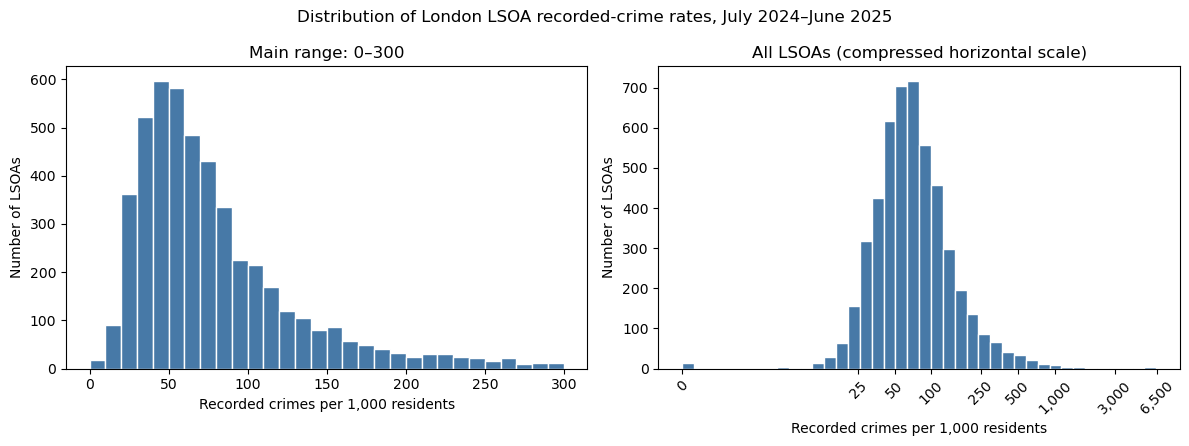

In [13]:
rate = london_rates["RatePer1000"]
print("Median rate per 1,000 residents:", round(rate.median(), 1))
print("Mean rate per 1,000 residents:", round(rate.mean(), 1))
print("Middle 50% of LSOAs:", round(rate.quantile(.25), 1), "to", round(rate.quantile(.75), 1))
print("LSOAs above 300 per 1,000:", (rate > 300).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(rate[rate <= 300], bins=30, color="#4779A7", edgecolor="white")
axes[0].set(title="Main range: 0–300", xlabel="Recorded crimes per 1,000 residents", ylabel="Number of LSOAs")

# log(1 + rate) keeps zero-valued areas on the chart while showing high extremes.
axes[1].hist(np.log1p(rate), bins=40, color="#4779A7", edgecolor="white")
ticks = np.array([0, 25, 50, 100, 250, 500, 1000, 3000, 6500])
axes[1].set_xticks(np.log1p(ticks))
axes[1].set_xticklabels([f"{v:,}" for v in ticks], rotation=45)
axes[1].set(title="All LSOAs (compressed horizontal scale)",
            xlabel="Recorded crimes per 1,000 residents", ylabel="Number of LSOAs")
fig.suptitle("Distribution of London LSOA recorded-crime rates, July 2024–June 2025")
plt.tight_layout()
plt.show()

**Comment.** The median is about **66.5 recorded crimes per 1,000 residents**, compared with a mean of **101.6**. Half the LSOAs fall between roughly **44.7 and 104.5**. The distribution is strongly right skewed: most areas have comparatively modest rates, but a small number have extremely high rates. In fact, **196 of 4,994 LSOAs** are above 300 per 1,000. The mean is pulled upwards by these high-rate areas, so the median gives a better picture of a typical LSOA.

### Mapping the rates across London

The GeoPackage contains an outline for each LSOA. I join those outlines to the rate table using the area codes (`LSOA21CD` in the geometry file and `LSOACode` in the population file).

On all maps, the colour scale runs from **0 to 300 crimes per 1,000 residents**. Rates higher than 300 appear in the darkest colour. This shared scale makes maps easier to compare; it also prevents a few unusually large values from washing out the differences between most areas. Exact extreme values are shown separately below.

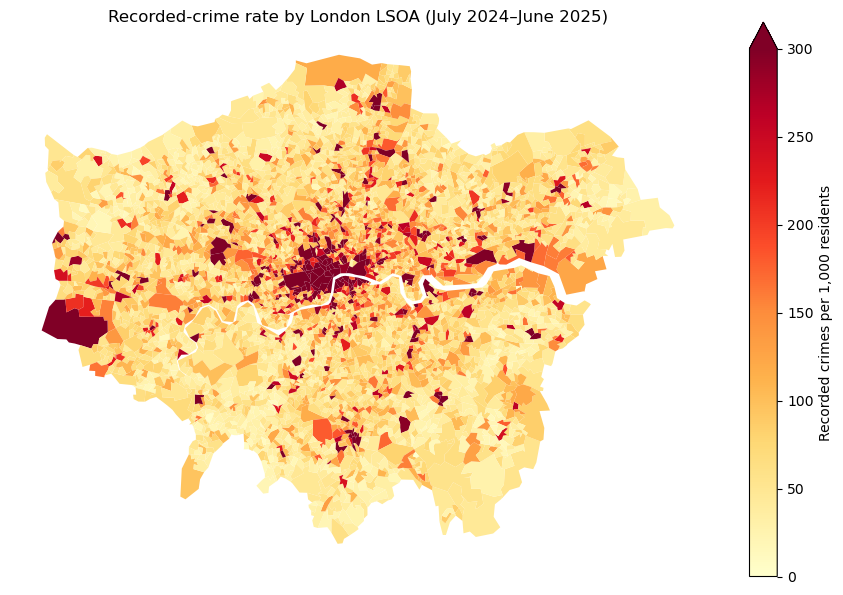

In [14]:
geometry = gpd.read_file(DATA_DIR / "LSOA_England_geom.gpkg")[["LSOA21CD", "geometry"]]
london_map = geometry.merge(
    london_rates, left_on="LSOA21CD", right_on="LSOACode",
    how="right", validate="one_to_one"
)
assert len(london_map) == len(london_rates)
assert london_map.geometry.notna().all()

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

colour_scale = Normalize(vmin=0, vmax=300)
colour_map = "YlOrRd"

fig, ax = plt.subplots(figsize=(9, 8))
london_map.plot(column="RatePer1000", cmap=colour_map,
                norm=colour_scale, ax=ax, linewidth=0)
ax.set(title="Recorded-crime rate by London LSOA (July 2024–June 2025)")
ax.set_axis_off()
bar = fig.colorbar(ScalarMappable(norm=colour_scale, cmap=colour_map),
                   ax=ax, shrink=.72, extend="max")
bar.set_label("Recorded crimes per 1,000 residents")
plt.tight_layout()
plt.show()

### A closer look at three boroughs

I chose **Westminster, Camden and Sutton** because their distributions look different. Westminster has several of the most extreme values; Camden also has some high rate areas but shows a mix; Sutton has a lower typical rate. I use **exactly the same colour scale** as the London map so that differences between the boroughs are visible rather than created by changing the legend.

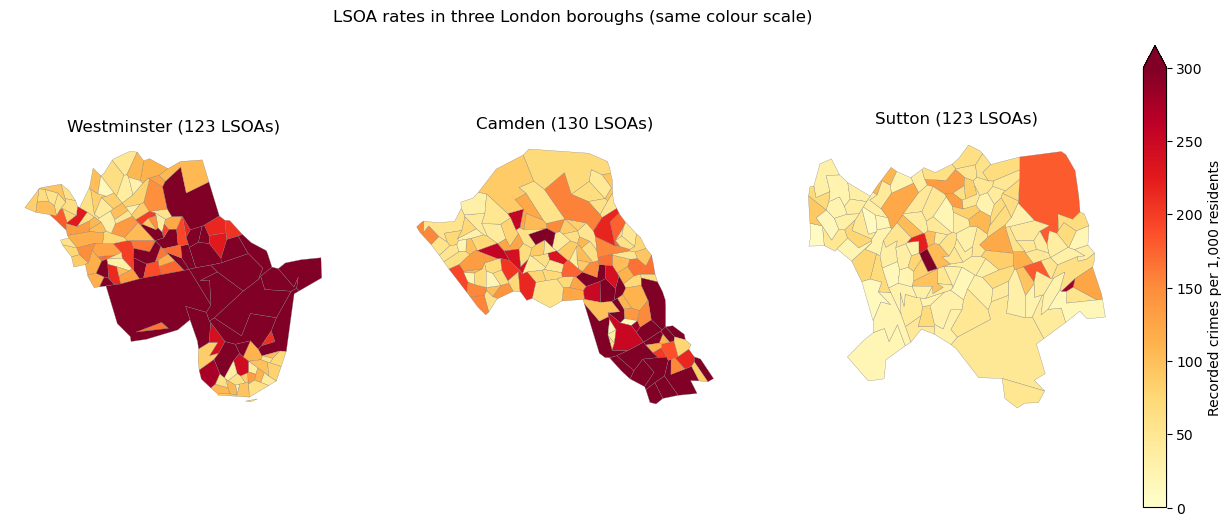

,LSOAs,MedianRate,HighestRate
PartOfName,,,
Camden,130,100.1,1849.4
Sutton,123,47.1,537.3
Westminster,123,115.3,6462.8


In [15]:
chosen_boroughs = ["Westminster", "Camden", "Sutton"]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, borough in zip(axes, chosen_boroughs):
    subset = london_map.loc[london_map["PartOfName"] == borough]
    subset.plot(column="RatePer1000", cmap=colour_map, norm=colour_scale,
                ax=ax, linewidth=.2, edgecolor="#777777")
    ax.set_title(f"{borough} ({len(subset)} LSOAs)")
    ax.set_axis_off()

bar = fig.colorbar(ScalarMappable(norm=colour_scale, cmap=colour_map),
                   ax=axes, fraction=.025, pad=.02, extend="max")
bar.set_label("Recorded crimes per 1,000 residents")
fig.suptitle("LSOA rates in three London boroughs (same colour scale)", y=.94)
plt.show()

borough_summary = (
    london_rates.loc[london_rates["PartOfName"].isin(chosen_boroughs)]
    .groupby("PartOfName")
    .agg(LSOAs=("LSOACode", "size"), MedianRate=("RatePer1000", "median"),
         HighestRate=("RatePer1000", "max"))
)
display(borough_summary.round(1))

**Comment on the maps.** Rates are not evenly distributed across London or within the same borough. Westminster has particularly strong hotspots, while Camden contains a mix of higher and lower rate LSOAs. Sutton's LSOAs are generally lighter on this common scale, although it has its own local high-rate areas. The borough medians reinforce the contrast: **115.3** for Westminster, **100.1** for Camden, and **47.1** for Sutton, all per 1,000 residents. Borough boundaries do not explain *why* these differences occur; the maps simply show where incidents were recorded.

### Checking the extremes

A map alone can hide very high values because they share the darkest colour. To see what drives them, I look up the recorded count and population behind the largest rates. I also check the lowest non zero rates and a few LSOAs with zero records.

In [16]:
columns = ["LSOAName", "PartOfName", "CrimeCount", "Total", "RatePer1000"]
print("Five highest rates:")
display(london_rates.nlargest(5, "RatePer1000")[columns].round(1))

print("Five lowest NON-ZERO rates:")
display(london_rates.loc[london_rates["CrimeCount"] > 0]
        .nsmallest(5, "RatePer1000")[columns].round(1))

print("Examples of LSOAs with no crimes recorded in this file:")
display(london_rates.loc[london_rates["CrimeCount"] == 0, columns].head(5))

Five highest rates:


,LSOAName,PartOfName,CrimeCount,Total,RatePer1000
33709,Westminster 013G,Westminster,14160,2191,6462.8
4480,Westminster 018A,Westminster,9684,1691,5726.8
4504,Westminster 013B,Westminster,10732,2016,5323.4
4482,Westminster 018C,Westminster,5801,1467,3954.3
32258,Newham 039D,Newham,3935,1233,3191.4


Five lowest NON-ZERO rates:


,LSOAName,PartOfName,CrimeCount,Total,RatePer1000
2207,Havering 014D,Havering,8,1654,4.8
2778,Kingston upon Thames 010A,Kingston upon Thames,8,1638,4.9
32086,Hounslow 031A,Hounslow,10,1794,5.6
3917,Sutton 006A,Sutton,12,1430,8.4
3267,Merton 015C,Merton,15,1488,10.1


Examples of LSOAs with no crimes recorded in this file:


,LSOAName,PartOfName,CrimeCount,Total,RatePer1000
406,Bexley 002C,Bexley,0,1336,0.0
1003,Croydon 030B,Croydon,0,1463,0.0
3424,Newham 011D,Newham,0,1561,0.0
3457,Newham 015E,Newham,0,1946,0.0
3554,Redbridge 032C,Redbridge,0,1839,0.0


**What stands out.** *Westminster 013G* has **14,160 recorded incidents** and **2,191 Census residents**, giving roughly **6,463 incidents per 1,000 residents**. *Westminster 018A* and *Westminster 013B* also have rates over 5,000, while *Newham 039D* is another high outlier. At the other end, *Havering 014D* has just **8 recorded incidents** and **1,654 residents**, or around **4.8 per 1,000**. There are also 13 LSOAs with no records in this file. Zero here means **no incident was recorded in the supplied data**, not proof that no crime occurred.

These extreme rates need careful interpretation. A rate above 1,000 is possible because it counts **incidents**, not distinct people: one place can have many recorded crimes during a year, and many people present there may be visitors rather than residents. Using residential population as the denominator can therefore produce especially large rates in busy areas. The data do not tell us whether that explains any particular hotspot, nor do they justify conclusions about residents' behaviour or individual risk. The Census population is also from 2021, several years before the crime period.

**Overall conclusion.** London LSOA crime rates vary substantially, even within single boroughs. The typical rate is much lower than the most extreme values, and both the distribution and maps show why it is important to look beyond a city wide average.

---


## Part 4 — Is the mix of crime types different between London regions?

### Interpretation

The word *mix* could mean several things. Here I take it to mean **the percentage of all recorded crimes in a region that belong to each crime type**. Each region's percentages therefore add up to 100%. This is more useful for comparing the types of crimes recorded than raw counts, because the regions have different numbers of records. It is **not** a comparison of crime rates per resident or the risk faced by an individual.

I use the five London Plan sub-regions listed under **“From 2011”** on the page specified in the coursework: [List of sub-regions used in the London Plan](https://en.wikipedia.org/wiki/List_of_sub-regions_used_in_the_London_Plan). There are 33 local authorities in total, including the City of London. I use the population file to match each crime's `LSOACode` to its borough (`PartOfName`), then assign the borough to a region. The population **counts** are not needed to work out the percentage mix.


In [17]:
# London Plan borough groupings (2011–present).
region_boroughs = {
    "Central": ["Camden", "City of London", "Kensington and Chelsea",
                "Islington", "Lambeth", "Southwark", "Westminster"],
    "East": ["Barking and Dagenham", "Bexley", "Greenwich", "Hackney",
             "Havering", "Lewisham", "Newham", "Redbridge", "Tower Hamlets",
             "Waltham Forest"],
    "North": ["Barnet", "Enfield", "Haringey"],
    "South": ["Bromley", "Croydon", "Kingston upon Thames", "Merton",
              "Sutton", "Wandsworth"],
    "West": ["Brent", "Ealing", "Hammersmith and Fulham", "Harrow",
             "Richmond upon Thames", "Hillingdon", "Hounslow"]
}

# Give each borough its region name.
borough_to_region = {}
for region, boroughs in region_boroughs.items():
    for borough in boroughs:
        borough_to_region[borough] = region

borough_lookup = london_population[["LSOACode", "PartOfName"]].copy()
assert borough_lookup["LSOACode"].is_unique
assert set(borough_lookup["PartOfName"]) == set(borough_to_region)

# Join each crime to its borough, then look up the region.
regional_crimes = crimes[["LSOACode", "CrimeType"]].merge(
    borough_lookup, on="LSOACode", how="left", validate="many_to_one"
)
regional_crimes["Region"] = regional_crimes["PartOfName"].map(borough_to_region)
assert regional_crimes["Region"].notna().all()
print("Crime records assigned to a region:", f"{len(regional_crimes):,}")
print("Regions:", sorted(regional_crimes["Region"].unique()))

Crime records assigned to a region: 902,579
Regions: ['Central', 'East', 'North', 'South', 'West']


### Counting crimes and calculating the mix

A cross-tabulation counts how often each crime type occurs in each region. I divide each count by **that region's total** and multiply by 100. As a check, the resulting percentages should sum to 100% for every region.


In [18]:
region_order = ["Central", "East", "North", "South", "West"]
region_counts = pd.crosstab(
    regional_crimes["Region"], regional_crimes["CrimeType"]
).reindex(region_order)

region_percent = region_counts.div(region_counts.sum(axis=1), axis=0) * 100
assert region_counts.to_numpy().sum() == len(crimes)
assert (region_percent.sum(axis=1).round(6) == 100).all()

print("Number of recorded crimes by region:")
display(region_counts.sum(axis=1).rename("Recorded crimes").to_frame())
print("Percentage breakdown by region (rounded to 1 decimal place):")
display(region_percent.round(1))

Number of recorded crimes by region:


,Recorded crimes
Region,
Central,260586
East,265914
North,84945
South,122103
West,169031


Percentage breakdown by region (rounded to 1 decimal place):


CrimeType,Bicycle theft,Burglary,Criminal damage and arson,Drugs,Other crime,Other theft,Possession of weapons,Public order,Robbery,Shoplifting,Theft from the person,Vehicle crime,Violence and sexual offences
Region,,,,,,,,,,,,,
Central,2.0,5.0,4.3,3.9,0.8,15.6,0.4,5.0,4.3,9.3,22.5,6.6,20.2
East,1.7,5.3,6.5,6.4,1.5,9.8,0.6,6.5,3.7,9.0,7.2,10.2,31.7
North,0.8,6.8,6.5,6.3,1.5,9.3,0.6,6.0,3.6,10.1,6.0,13.1,29.5
South,1.2,5.9,7.6,5.4,1.5,8.8,0.6,6.8,2.7,12.0,3.4,11.0,33.0
West,1.5,5.6,6.8,5.1,2.2,9.7,0.5,6.7,2.9,10.4,5.0,11.6,32.0


### Plot 1 — Composition of recorded crimes within each region

Each horizontal bar represents **all recorded incidents in one region (100%)**. The segments show how much of that region's total belongs to each crime type. The bar lengths are deliberately equal: the chart is about *composition*, not the number of crimes.


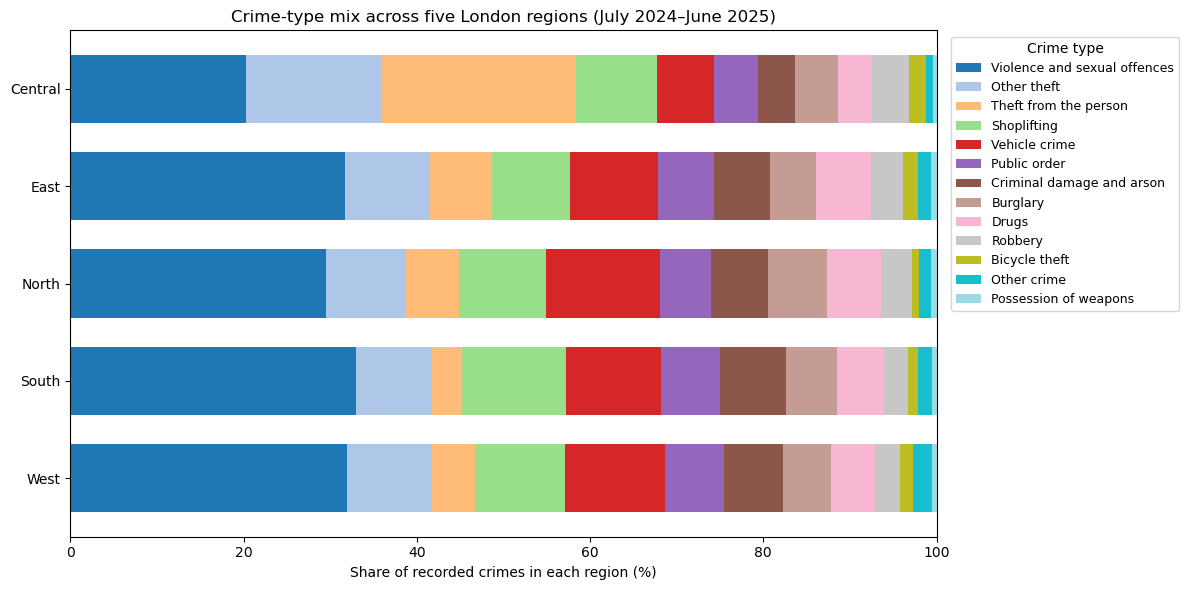

In [19]:
# Sort the types by their frequency across London so the legend is easier to follow.
type_order = region_counts.sum(axis=0).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 6))
region_percent[type_order].plot.barh(stacked=True, ax=ax, width=0.7, colormap="tab20")
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Share of recorded crimes in each region (%)",
       ylabel="", title="Crime-type mix across five London regions (July 2024–June 2025)")
ax.legend(title="Crime type", bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=9)
plt.tight_layout()
plt.show()

**Comment.** Central London has a noticeably different mix from the other regions. *Theft from the person* accounts for **22.5%** of its recorded crimes, against only **3.4%** in South London. By contrast, *violence and sexual offences* make up **20.2%** of the Central total but **33.0%** in South London. This is a difference in the **shares of recorded incidents**, not evidence that any individual faces a higher or lower risk.

### Plot 2 — Which types differ most from the London-wide mix?

The stacked chart shows the whole mix but small differences can be hard to spot. To highlight them, I subtract each crime type's **London-wide percentage** from its percentage in each region. The result is a difference in **percentage points**: positive numbers mean the type has a larger share in that region than London overall; negative numbers mean a smaller share. The heatmap shows all 13 crime types.


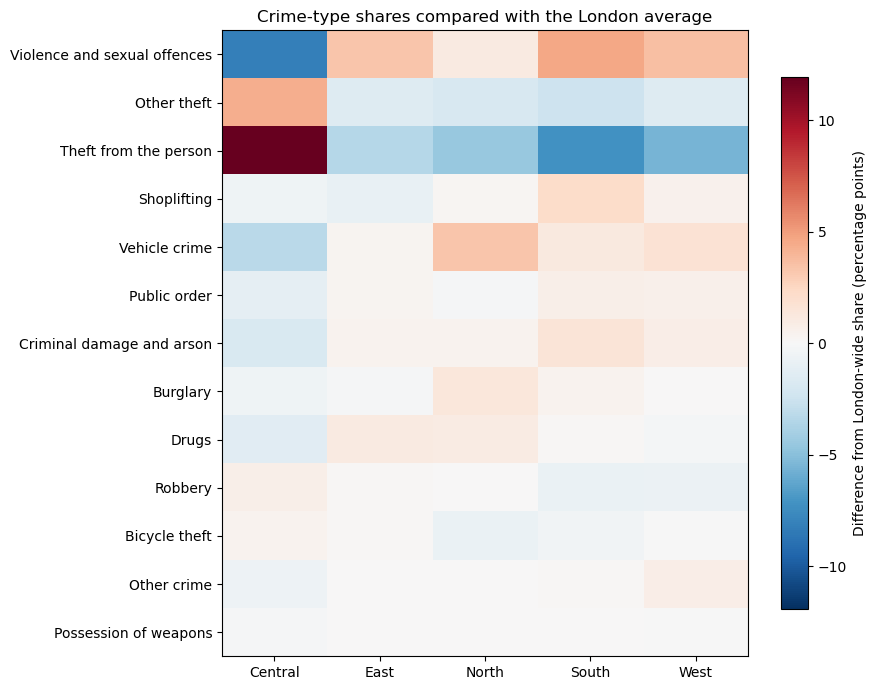

In [20]:
# Use the entire London dataset to obtain the comparison percentages.
london_percent = region_counts.sum(axis=0) / region_counts.to_numpy().sum() * 100
share_difference = region_percent.sub(london_percent, axis=1)

# Put the most common types at the top. The scale is centred on zero.
heatmap_values = share_difference[type_order].T
largest_difference = abs(heatmap_values.to_numpy()).max()
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(heatmap_values, cmap="RdBu_r", aspect="auto",
                  vmin=-largest_difference, vmax=largest_difference)
ax.set_xticks(range(len(heatmap_values.columns)), labels=heatmap_values.columns)
ax.set_yticks(range(len(heatmap_values.index)), labels=heatmap_values.index)
ax.set_title("Crime-type shares compared with the London average")
bar = fig.colorbar(image, ax=ax, shrink=0.85)
bar.set_label("Difference from London-wide share (percentage points)")
plt.tight_layout()
plt.show()

**Comment.** The biggest departure from the London-wide mix is *theft from the person* in Central London: it makes up **22.5%** of records there, compared with **10.6%** across London, a difference of about **+11.9 percentage points**. Central London's share of *violence and sexual offences* is about **8.2 points below** the London average. North London has a comparatively high share of *vehicle crime* (**13.1%**, versus **9.8%** across London).

**Conclusion and limitations.** The mix of recorded crime clearly differs between the five regions, with Central London standing out most. However, each percentage depends on the types and number of incidents **reported and recorded** in that region. Visitors, workplaces, differences in reporting and other factors may contribute to these patterns. This analysis does not control for population or visitor numbers and cannot explain why the regional differences occur. The records cover just one year, so these findings should not be taken as permanent characteristics of the regions.

---

## Part 5 — Does the proportion of young people correlate with the crime rate?

### Interpretation and approach

I define **young people as residents aged 15–24**, adding the Census counts in `Age15to19` and `Age20to24`. This gives an age group that is available directly from the supplied five-year bands. Other definitions of “young” are possible, so this choice matters.

For each London LSOA, I calculate **youth proportion (%) = 100 × residents aged 15–24 / all residents**. I compare it with the **annual recorded-crime rate per 1,000 residents** already calculated in Part 3. Each LSOA is one observation, and all crime types are included. I use Pearson's correlation coefficient to describe the *linear* relationship. This is a descriptive comparison, not a test of significance or evidence of cause and effect.

In [21]:
# The rate table from Part 3 already includes the Census age counts.
youth_rates = london_rates.copy()
youth_rates["YouthCount"] = (
    youth_rates["Age15to19"] + youth_rates["Age20to24"]
)
youth_rates["YouthPercent"] = (
    youth_rates["YouthCount"] / youth_rates["Total"] * 100
)

assert youth_rates["Total"].gt(0).all()
assert youth_rates["YouthCount"].le(youth_rates["Total"]).all()
assert youth_rates[["YouthPercent", "RatePer1000"]].notna().all().all()

print("LSOAs included:", len(youth_rates))
print("Median youth percentage:", round(youth_rates["YouthPercent"].median(), 1))
print("Range of youth percentages:",
      round(youth_rates["YouthPercent"].min(), 1), "to",
      round(youth_rates["YouthPercent"].max(), 1))

LSOAs included: 4994
Median youth percentage: 11.5
Range of youth percentages: 3.8 to 59.3


### Scatter plot and correlation

The horizontal axis shows the percentage of residents aged 15–24; the vertical axis shows the recorded-crime rate per 1,000 residents. The left-hand plot includes **every London LSOA**. Because a small number of rates are unusually high, the right-hand plot shows a closer view of LSOAs at or below the 99th percentile of crime rates. The Pearson coefficient is still calculated using **all LSOAs**, not just those in the closer view.

Pearson correlation (all London LSOAs): 0.195
99th percentile of the crime rate: 621.2 per 1,000
LSOAs in the closer view: 4,944 of 4,994


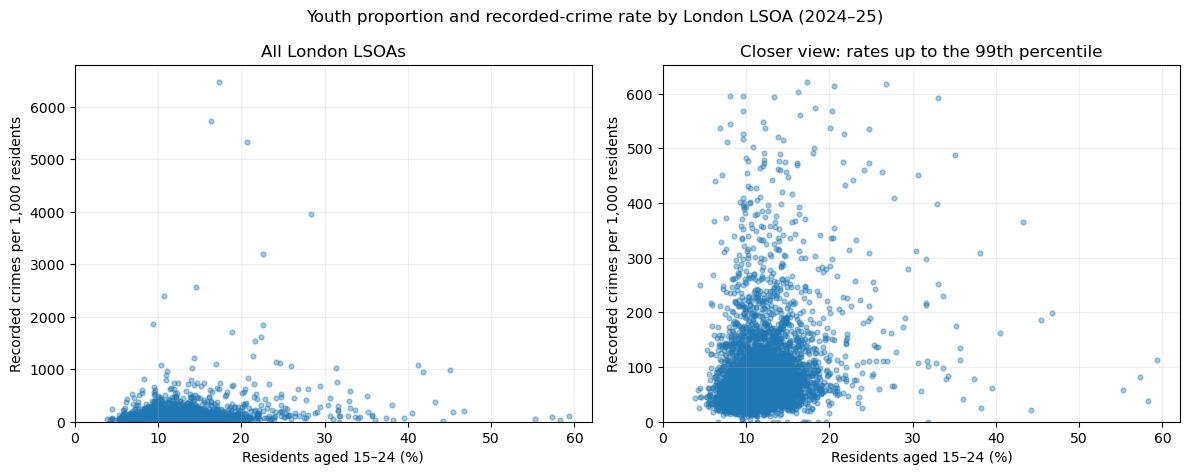

In [22]:
pearson_r = youth_rates["YouthPercent"].corr(youth_rates["RatePer1000"])
rate_cutoff = youth_rates["RatePer1000"].quantile(0.99)
closer_view = youth_rates.loc[youth_rates["RatePer1000"] <= rate_cutoff]

print(f"Pearson correlation (all London LSOAs): {pearson_r:.3f}")
print(f"99th percentile of the crime rate: {rate_cutoff:.1f} per 1,000")
print(f"LSOAs in the closer view: {len(closer_view):,} of {len(youth_rates):,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].scatter(youth_rates["YouthPercent"], youth_rates["RatePer1000"],
                s=12, alpha=0.4)
axes[0].set_title("All London LSOAs")

axes[1].scatter(closer_view["YouthPercent"], closer_view["RatePer1000"],
                s=12, alpha=0.4)
axes[1].set_title("Closer view: rates up to the 99th percentile")

for ax in axes:
    ax.set_xlabel("Residents aged 15–24 (%)")
    ax.set_ylabel("Recorded crimes per 1,000 residents")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)

fig.suptitle("Youth proportion and recorded-crime rate by London LSOA (2024–25)")
plt.tight_layout()
plt.show()

**What the data show.** The Pearson correlation is about **+0.195**, indicating a **weak positive linear relationship** across the 4,994 London LSOAs. Some areas with larger youth proportions have higher recorded crime rates, but the points are widely scattered, and there are many exceptions. In the full plot, a few exceptionally high crime rates also compress the main cluster of observations. The closer view makes the variation within that cluster easier to see; it does not change the reported correlation.

This result does **not** establish that young residents commit the recorded crimes. It compares characteristics of **places**, not the ages of offenders or victims. An LSOA may contain shops, transport hubs or visitors who are not represented by its resident population.

### Four contrasting LSOAs

To see why the correlation is not a simple rule, I selected four areas that illustrate different combinations of **high/low youth proportion** and **high/low recorded-crime rate**. Here, *high* means above the upper quartile (75th percentile), and *low* means below the lower quartile (25th percentile) across London's LSOAs. The examples were selected for illustration, not because they represent their whole borough.

In [23]:
# Four illustrative areas, identified by their unique LSOA codes.
example_codes = {
    "High youth / high crime": "E01035711",  # Camden 026E
    "High youth / low crime": "E01003881",   # Richmond upon Thames 016B
    "Low youth / high crime": "E01004761",  # Westminster 018D
    "Low youth / low crime": "E01004598",   # Wandsworth 025D
}

examples = youth_rates.set_index("LSOACode").loc[list(example_codes.values())].copy()
examples.insert(0, "Comparison", list(example_codes))

low_youth, high_youth = youth_rates["YouthPercent"].quantile([0.25, 0.75])
low_crime, high_crime = youth_rates["RatePer1000"].quantile([0.25, 0.75])

assert examples.iloc[0]["YouthPercent"] >= high_youth and examples.iloc[0]["RatePer1000"] >= high_crime
assert examples.iloc[1]["YouthPercent"] >= high_youth and examples.iloc[1]["RatePer1000"] <= low_crime
assert examples.iloc[2]["YouthPercent"] <= low_youth and examples.iloc[2]["RatePer1000"] >= high_crime
assert examples.iloc[3]["YouthPercent"] <= low_youth and examples.iloc[3]["RatePer1000"] <= low_crime

print(f"Low/high youth quartiles: {low_youth:.1f}% / {high_youth:.1f}%")
print(f"Low/high crime-rate quartiles: {low_crime:.1f} / {high_crime:.1f} per 1,000")
display(examples[["Comparison", "LSOAName", "PartOfName", "YouthCount",
                  "Total", "YouthPercent", "CrimeCount", "RatePer1000"]].round(1))

Low/high youth quartiles: 9.7% / 13.7%
Low/high crime-rate quartiles: 44.7 / 104.5 per 1,000


,Comparison,LSOAName,PartOfName,YouthCount,Total,YouthPercent,CrimeCount,RatePer1000
LSOACode,,,,,,,,
E01035711,High youth / high crime,Camden 026E,Camden,1095,2433,45.0,2390,982.3
E01003881,High youth / low crime,Richmond upon Thames 016B,Richmond upon Thames,781,1768,44.2,37,20.9
E01004761,Low youth / high crime,Westminster 018D,Westminster,114,1207,9.4,2251,1865.0
E01004598,Low youth / low crime,Wandsworth 025D,Wandsworth,130,2147,6.1,40,18.6


**Reading the four cases.** *Camden 026E* has a high proportion of 15–24-year-olds (**45.0%**) and a high recorded-crime rate (**982.3 per 1,000**). But *Richmond upon Thames 016B* has an almost equally high youth proportion (**44.2%**) with a much lower rate (**20.9 per 1,000**). The opposite contrast is also clear: *Westminster 018D* has a relatively low youth proportion (**9.4%**) but a very high rate (**1,865.0 per 1,000**), while *Wandsworth 025D* has both a low youth proportion (**6.1%**) and a low crime rate (**18.6 per 1,000**). The underlying counts are included in the table above so the high rates can be checked.

**Conclusion and limitations.** There is a weak positive association, but youth proportion alone does not explain the wide differences in recorded crime rates. The number of crimes relates to where incidents were recorded, not necessarily where offenders or victims live. Population counts come from 2021 but crime records are from 2024–25, and reporting practices may differ by place and crime type. In particular, central or busy locations can record many incidents relative to their resident populations. These are area-level comparisons, so the results should not be used to make claims about individual young people or the causes of crime.

---

**Overall:** The five parts describe recorded crime from different angles outcomes, time, small area rates, regional crime type mix, and age composition. The results are descriptive, and their interpretation is limited by the coverage and nature of the supplied records.